# 05 – Existing Bubble Tea Shops

Finds existing bubble tea shops in Toronto from OpenStreetMap. These are the
competitors for site selection, and later they serve as the "good location"
examples the ML model learns from.

**Method**
- Downloaded all cafes, fast food places, restaurants, and tea/beverage shops
  in the city (8,187 places).
- Kept places tagged `cuisine=bubble_tea` or whose name matches a known bubble
  tea brand. The brand list was expanded after reviewing tagged results.
- Excluded non-bubble-tea matches (e.g., a tanghulu dessert shop).
- Converted building outlines to center points and removed duplicates
  (same name within 30 m).

**Result:** 178 shops, clustered downtown, along Yonge Street in North York,
and in northeast Scarborough.

**Limitation:** OpenStreetMap is volunteer-mapped, so some shops are missing.
Cross-checking with another source (e.g., Google Places) would improve coverage.

**Output:** `data/processed/bubble_tea.gpkg`

In [11]:
import geopandas as gpd
import pandas as pd
import osmnx as ox

city = gpd.read_file("../data/processed/city_boundary.gpkg")
hexes = gpd.read_file("../data/processed/hex_features.gpkg")

# OSMnx needs the boundary in latitude/longitude
polygon = city.to_crs(epsg=4326).geometry.iloc[0]

In [12]:
tags = {
    "amenity": ["cafe", "fast_food", "restaurant"],
    "shop": ["tea", "beverages"],
}
places = ox.features_from_polygon(polygon, tags=tags)
print("Places downloaded:", len(places))

Places downloaded: 8187


In [13]:
BRANDS = [
    "bubble", "boba", "chatime", "coco fresh", "gong cha", "the alley", "kung fu tea",
    "presotea", "sharetea", "tiger sugar", "xing fu tang", "real fruit", "machi machi",
    "yi fang", "truedan", "heytea", "happy lemon", "ten ren", "tsaocaa", "chagee",
    # Added after reviewing tagged results
    "palgong", "chicha san chen", "royaltea", "shuyi", "incha", "cha miao",
    "formocha", "ding tea", "tealive",
]
EXCLUDE = ["tanghulu"]

name = places["name"].fillna("").str.lower() if "name" in places else pd.Series("", index=places.index)
cuisine = places["cuisine"].fillna("").str.lower() if "cuisine" in places else pd.Series("", index=places.index)

is_bubble_tea = (
    (cuisine.str.contains("bubble_tea") | name.str.contains("|".join(BRANDS)))
    & ~name.str.contains("|".join(EXCLUDE))
)
bubble = places[is_bubble_tea].copy()
print("Bubble tea shops found:", len(bubble))

# Look at the uncertain one before deciding
bubble.loc[name[is_bubble_tea].str.contains("sweet shady"), ["name", "amenity", "cuisine"]]

Bubble tea shops found: 180


,,name,amenity,cuisine
element,id,,,
node,1392114833,Sweet Shady Shack,cafe,bubble_tea


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

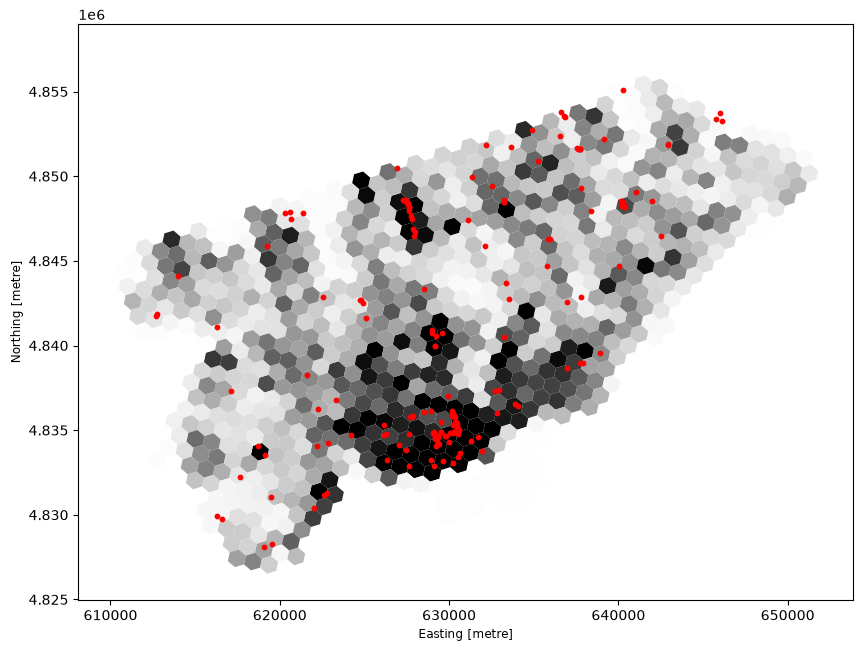

In [14]:
# Some shops are mapped as building outlines, so use their center point
bubble = bubble.to_crs(epsg=32617)
bubble["geometry"] = bubble.geometry.centroid
bubble = bubble[["name", "geometry"]].reset_index(drop=True)

vmax = hexes["pop_density"].quantile(0.95)
ax = hexes.plot(column="pop_density", cmap="Greys", vmax=vmax, figsize=(10, 10))
bubble.plot(ax=ax, color="red", markersize=10)

In [15]:
buffers = bubble.copy()
buffers["geometry"] = bubble.buffer(30)

near = gpd.sjoin(bubble, buffers, predicate="within")
dupes = near[(near.index < near["index_right"]) & (near["name_left"] == near["name_right"])]

print("Duplicates found:", len(dupes))
bubble = bubble.drop(dupes["index_right"].unique()).reset_index(drop=True)
print("Bubble tea shops after cleaning:", len(bubble))

Duplicates found: 2
Bubble tea shops after cleaning: 178


In [16]:
bubble.to_file("../data/processed/bubble_tea.gpkg", driver="GPKG")
print("Saved")

Saved
